# Life Insurance Pricing & Monte Carlo Risk Modelling

This project develops an actuarial pricing model for term life insurance, combining UK mortality data, expected present value calculations, Monte Carlo simulation and sensitivity analysis.

The objective is to understand how mortality risk, policyholder characteristics and financial assumptions influence insurance premiums and portfolio risk.

## Project Structure

1. **Mortality Modelling** — Life tables, death probabilities and survival probabilities.
2. **Actuarial Pricing** — Expected claims, discounting and premium calculations.
3. **Monte Carlo Simulation** — Simulating claim outcomes and quantifying insurer risk.
4. **Sensitivity Analysis** — Investigating how changes in assumptions affect pricing and risk.

We will use UK life tables from the Office for National Statistics and develop the mathematical theory alongside the Python implementation.

## 1. Mortality Modelling

### 1.1 Mortality Probabilities and Life Tables

Life insurance pricing requires an estimate of the probability that a policyholder dies during a specified period. These probabilities are typically obtained from actuarial life tables, which describe mortality and survival patterns across different ages.

Let $T_x$ denote the remaining lifetime of an individual aged exactly $x$.

The **one-year mortality probability** is defined as

$$
q_x = P(T_x \leq 1).
$$

Equivalently, $q_x$ is the probability that an individual aged $x$ dies before reaching age $x+1$.

The corresponding **one-year survival probability** is

$$
p_x = P(T_x > 1) = 1-q_x.
$$

Life tables also commonly contain:

- $l_x$: the number of individuals surviving to exact age $x$ in a hypothetical cohort.
- $d_x$: the number of individuals dying between exact ages $x$ and $x+1$.

These quantities satisfy

$$
d_x = l_x-l_{x+1},
$$

and therefore

$$
q_x = \frac{d_x}{l_x} = 1-\frac{l_{x+1}}{l_x}.
$$

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.precision", 6)

In [4]:
import pandas as pd

file_path = "data/nltuk198020223.xlsx"

# Open the Excel workbook
excel_file = pd.ExcelFile(file_path)

# Display all worksheet names
print("Available worksheets:\n")

for sheet in excel_file.sheet_names:
    print(sheet)

Available worksheets:

Contents
Notes
Notation
Methodology
2022-2024
2021-2023
2020-2022
2019-2021
2018-2020
2017-2019
2016-2018
2015-2017
2014-2016
2013-2015
2012-2014
2011-2013
2010-2012
2009-2011
2008-2010
2007-2009
2006-2008
2005-2007
2004-2006
2003-2005
2002-2004
2001-2003
2000-2002
1999-2001
1998-2000
1997-1999
1996-1998
1995-1997
1994-1996
1993-1995
1992-1994
1991-1993
1990-1992
1989-1991
1988-1990
1987-1989
1986-1988
1985-1987
1984-1986
1983-1985
1982-1984
1981-1983
1980-1982


In [6]:
# Load the 2022–2024 UK life table
mortality_raw = pd.read_excel(
    file_path,
    sheet_name="2022-2024",
    header=None
)

# Inspect the first 20 rows and 15 columns
display(mortality_raw.iloc[:20, :15])

# Check the dimensions
print("Dataset dimensions:", mortality_raw.shape)

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,"National Life Tables, United Kingdom, period e...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"This worksheet contains two tables, presented ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,This worksheet uses notation in the column hea...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Back to contents,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Males,NaN,NaN,NaN,NaN,NaN,NaN,Females,NaN,NaN,NaN,NaN,NaN
5,age,mx,qx,lx,dx,ex,NaN,age,mx,qx,lx,dx,ex
6,0,0.004612,0.004602,100000,460.2,79.12,NaN,0,0.003638,0.003631,100000,363.1,83.02
7,1,0.000247,0.000247,99539.8,24.6,78.49,NaN,1,0.000207,0.000206,99636.9,20.6,82.32
8,2,0.000177,0.000177,99515.3,17.6,77.51,NaN,2,0.000137,0.000137,99616.3,13.7,81.34
9,3,0.000115,0.000115,99497.6,11.4,76.52,NaN,3,0.000099,0.000099,99602.6,9.8,80.35


Dataset dimensions: (107, 13)


### 1.2.1 Data Preparation

The ONS national life tables provide mortality statistics separately for males and females across different ages.

We extract the following quantities:

- $x$: Age of the individual.
- $q_x^{(m)}$: One-year mortality probability for males.
- $q_x^{(f)}$: One-year mortality probability for females.
- $l_x^{(m)}$: Number of male survivors at exact age $x$.
- $l_x^{(f)}$: Number of female survivors at exact age $x$.

The mortality probabilities are conditional on survival to age $x$ and satisfy

$$
0 \leq q_x \leq 1.
$$

We distinguish between the central mortality rate $m_x$ and the probability of death $q_x$. Although these quantities may be numerically similar at younger ages, they are not generally equivalent.

For actuarial pricing, we use $q_x$ because it directly represents the probability of a death occurring during the following year.

The data are derived from UK period life tables for 2022–2024. We initially assume that these age-specific mortality probabilities remain unchanged over future calendar years.

In [7]:
# Extract mortality data from the ONS worksheet
mortality = mortality_raw.iloc[6:, [0, 2, 3, 7, 9, 10]].copy()

# Assign descriptive column names
mortality.columns = [
    "Age",
    "Male_qx",
    "Male_lx",
    "Female_Age",
    "Female_qx",
    "Female_lx"
]

# Convert columns to numeric values
mortality = mortality.apply(pd.to_numeric, errors="coerce")

# Remove rows without valid age or mortality data
mortality = mortality.dropna(
    subset=["Age", "Male_qx", "Female_qx"]
)

# Verify male and female ages are aligned
assert (mortality["Age"] == mortality["Female_Age"]).all()

# Remove duplicate age column
mortality = mortality.drop(columns="Female_Age")

# Convert age to integer and reset index
mortality["Age"] = mortality["Age"].astype(int)
mortality = mortality.reset_index(drop=True)

# Validate mortality probabilities
assert mortality["Age"].is_unique
assert mortality["Age"].is_monotonic_increasing
assert mortality[["Male_qx", "Female_qx"]].ge(0).all().all()
assert mortality[["Male_qx", "Female_qx"]].le(1).all().all()

display(mortality.head(10))

print("Number of ages:", len(mortality))
print("Age range:", mortality["Age"].min(),
      "to", mortality["Age"].max())

,Age,Male_qx,Male_lx,Female_qx,Female_lx
0,0,0.004602,100000.0,0.003631,100000.0
1,1,0.000247,99539.8,0.000206,99636.9
2,2,0.000177,99515.3,0.000137,99616.3
3,3,0.000115,99497.6,0.000099,99602.6
4,4,0.000100,99486.2,0.000081,99592.8
5,5,0.000097,99476.3,0.000070,99584.7
6,6,0.000080,99466.7,0.000075,99577.7
7,7,0.000080,99458.7,0.000062,99570.2
8,8,0.000079,99450.7,0.000061,99564.0
9,9,0.000091,99442.9,0.000060,99558.0


Number of ages: 101
Age range: 0 to 100


In [8]:
# Compare mortality probabilities at selected ages
selected_ages = [20, 30, 40, 50, 60, 70, 80, 90]

mortality_comparison = mortality[
    mortality["Age"].isin(selected_ages)
][["Age", "Male_qx", "Female_qx"]].copy()

# Express probabilities as percentages
mortality_comparison["Male (%)"] = (
    mortality_comparison["Male_qx"] * 100
)

mortality_comparison["Female (%)"] = (
    mortality_comparison["Female_qx"] * 100
)

display(
    mortality_comparison[
        ["Age", "Male (%)", "Female (%)"]
    ].round(4)
)

,Age,Male (%),Female (%)
20,20,0.0457,0.0222
30,30,0.0769,0.0371
40,40,0.1681,0.0961
50,50,0.3711,0.2364
60,60,0.7761,0.5019
70,70,1.9527,1.2715
80,80,5.2665,3.7938
90,90,16.6653,13.4302


### 1.3 Multi-Year Survival and Death Probabilities

Life insurance contracts commonly provide coverage over multiple years. Consequently, actuarial pricing requires the probability that an individual survives or dies over a specified period.

Let $T_x$ denote the remaining lifetime of an individual aged exactly $x$.

The probability of surviving at least $t$ years is defined as

$$
{}_tp_x = P(T_x > t).
$$

For integer $t \geq 1$, survival over $t$ years requires surviving each successive year. Applying the multiplication rule for conditional probabilities gives

$$
{}_tp_x = \prod_{k=0}^{t-1}p_{x+k}.
$$

Since $p_x = 1-q_x$, we obtain

$$
\boxed{{}_tp_x = \prod_{k=0}^{t-1}(1-q_{x+k})}.
$$

The probability of dying within the next $t$ years is therefore

$$
\boxed{{}_tq_x = 1-{}_tp_x}.
$$

#### Probability of Death During a Particular Policy Year

For a life aged $x$, the probability of surviving the first $k$ years and dying during policy year $k+1$ is

$$
P(k < T_x \leq k+1)
= {}_kp_x q_{x+k}.
$$

Here:

- ${}_kp_x$ is the probability of surviving the first $k$ years.
- $q_{x+k}$ is the conditional probability of dying during the following year.

For $k=0$, we define ${}_0p_x=1$.

This decomposition is fundamental to term life insurance pricing because the insurer pays a death benefit only if death occurs during the coverage period.

In [10]:
def survival_probability(age, years, sex="Male"):
    """
    Calculate the probability of surviving a given
    number of complete years using ONS mortality data.
    """
    if not isinstance(age, (int, np.integer)):
        raise ValueError("Age must be an integer.")

    if not isinstance(years, (int, np.integer)) or years < 0:
        raise ValueError("Years must be a non-negative integer.")

    if sex not in ("Male", "Female"):
        raise ValueError("Sex must be 'Male' or 'Female'.")

    qx = mortality.set_index("Age")[f"{sex}_qx"]

    required_ages = range(age, age + years)

    if not all(a in qx.index for a in required_ages):
        raise ValueError("Requested ages exceed available mortality data.")

    annual_survival = 1 - qx.loc[list(required_ages)]

    return float(np.prod(annual_survival))


# Example: 10-year survival probabilities at age 40
male_survival = survival_probability(40, 10, "Male")
female_survival = survival_probability(40, 10, "Female")

print(f"Male 10-year survival probability: {male_survival:.4%}")
print(f"Female 10-year survival probability: {female_survival:.4%}")

Male 10-year survival probability: 97.6307%
Female 10-year survival probability: 98.5578%


In [11]:
def death_probability(age, years, sex="Male"):
    """
    Calculate the probability of death within
    the next specified number of years.
    """
    return 1 - survival_probability(age, years, sex)


# Compare 10-year death probabilities
for age in [20, 30, 40, 50, 60, 70]:
    male = death_probability(age, 10, "Male")
    female = death_probability(age, 10, "Female")

    print(
        f"Age {age}: "
        f"Male = {male:.3%}, "
        f"Female = {female:.3%}"
    )

Age 20: Male = 0.576%, Female = 0.258%
Age 30: Male = 1.096%, Female = 0.588%
Age 40: Male = 2.369%, Female = 1.442%
Age 50: Male = 5.153%, Female = 3.306%
Age 60: Male = 11.454%, Female = 7.697%
Age 70: Male = 26.920%, Female = 19.281%


### 1.4 Visualising Mortality Risk

#### 1.4.1 Annual Mortality Probabilities

We first examine how the one-year mortality probability $q_x$ varies with age and sex.

Mortality risk is generally low throughout childhood and early adulthood, before increasing substantially at older ages.

Understanding this relationship is essential for life insurance pricing because policyholders of different ages have different expected claim costs.

We compare male and female mortality probabilities using the ONS 2022–2024 period life tables.

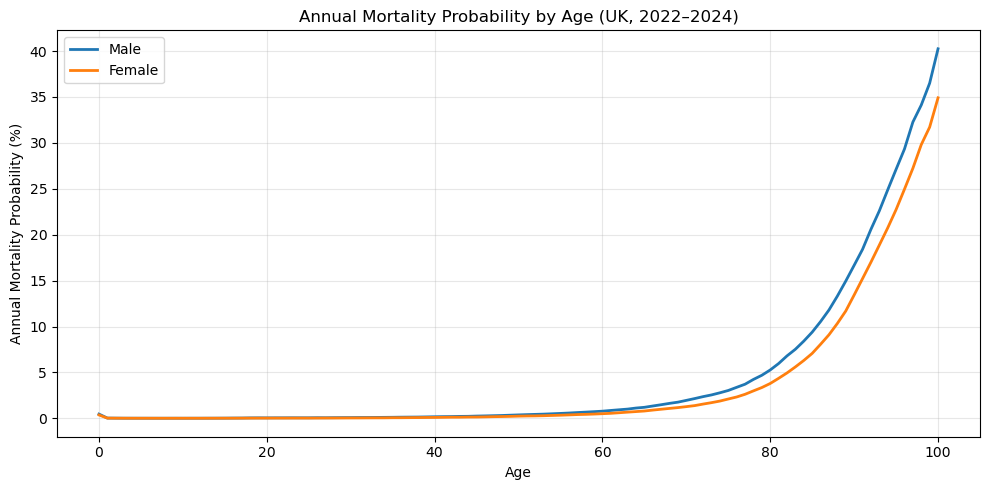

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    mortality["Age"],
    mortality["Male_qx"] * 100,
    label="Male",
    linewidth=2
)

ax.plot(
    mortality["Age"],
    mortality["Female_qx"] * 100,
    label="Female",
    linewidth=2
)

ax.set(
    title="Annual Mortality Probability by Age (UK, 2022–2024)",
    xlabel="Age",
    ylabel="Annual Mortality Probability (%)"
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### 1.4.2 Ten-Year Mortality Probabilities

For a term life insurance policy, the insurer is concerned with the probability of death during the entire coverage period.

For a policyholder aged $x$ with a 10-year term, this probability is

$$
{}_{10}q_x = 1-\prod_{k=0}^{9}(1-q_{x+k}).
$$

We evaluate this probability across different starting ages to understand how mortality risk changes with the age at which a policy is issued.

The calculation assumes that age-specific mortality probabilities remain constant over calendar time, consistent with the use of period life tables.

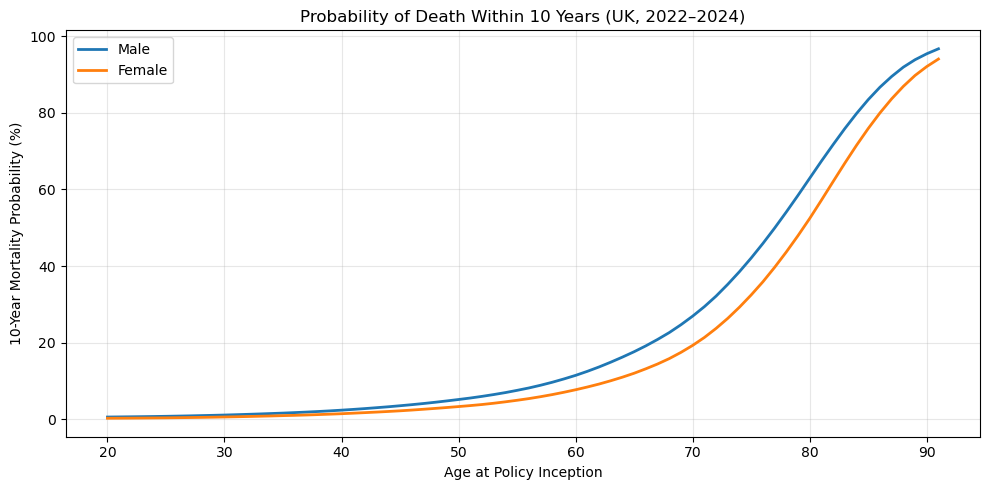

In [14]:
# Calculate 10-year mortality probabilities
# Ages up to 91 are supported by the available table (0–100).

ages = np.arange(20, 92)

male_10yr = [
    death_probability(int(age), 10, "Male")
    for age in ages
]

female_10yr = [
    death_probability(int(age), 10, "Female")
    for age in ages
]

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    ages,
    np.array(male_10yr) * 100,
    label="Male",
    linewidth=2
)

ax.plot(
    ages,
    np.array(female_10yr) * 100,
    label="Female",
    linewidth=2
)

ax.set(
    title="Probability of Death Within 10 Years (UK, 2022–2024)",
    xlabel="Age at Policy Inception",
    ylabel="10-Year Mortality Probability (%)"
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 1.5 Key Findings

Using the ONS national life tables for 2022–2024, we constructed a mortality model describing annual and multi-year death probabilities.

The analysis establishes several important relationships:

1. **Age-dependent mortality:** Mortality probabilities generally increase with age, particularly at older ages, implying higher expected claim costs for older policyholders.

2. **Differences by sex:** The mortality tables allow us to examine differences in mortality experience between males and females. These differences are relevant to modelling expected claims, although their use in individual insurance pricing is subject to applicable regulation.

3. **Multi-year risk:** The probability of death during a term insurance contract depends on the entire sequence of annual mortality probabilities, rather than the probability in the first year alone.

4. **Actuarial application:** The probability of death during policy year $k+1$ is

$$
P(k<T_x\leq k+1)={}_kp_xq_{x+k}.
$$

This provides the probability weights required to calculate the expected present value of future death benefits.

## 2. Actuarial Pricing

### 2.1 Expected Present Value of Death Benefits

We consider a term life insurance contract with the following characteristics:

- Initial policyholder age: $x=40$.
- Policy duration: $n=10$ years.
- Death benefit: $B=£100,000$.
- Annual effective interest rate: $i=0.04$.

The insurer pays the death benefit if the policyholder dies during the coverage period. For simplicity, we assume that the benefit is paid at the end of the policy year in which death occurs.

#### Discounting Future Claims

The present value of £1 received in $t$ years is

$$
v^t=(1+i)^{-t},
$$

where $v=(1+i)^{-1}$ is the annual discount factor.

#### Expected Present Value

The probability of death during policy year $k+1$ is

$$
P(k<T_x\leq k+1)={}_kp_xq_{x+k}.
$$

If death occurs during this year, the present value of the death benefit is

$$
Bv^{k+1}.
$$

Therefore, the expected present value (EPV) of the insurer's death benefit payments is

$$
\boxed{
EPV_{\text{claims}}
=
B\sum_{k=0}^{n-1}
v^{k+1}{}_kp_xq_{x+k}
}.
$$

Here:

- $B$ is the sum assured.
- $n$ is the policy term.
- $v$ is the annual discount factor.
- ${}_kp_x$ is the probability of surviving the first $k$ years.
- $q_{x+k}$ is the conditional probability of death during policy year $k+1$.

This expression weights each possible claim payment by its probability of occurrence and discounts it to the policy inception date.

The result represents the expected present value of claims for one policy, before expenses and risk loadings.

In [15]:
def expected_present_value(age, term, benefit,
                           interest_rate, sex="Male"):
    """
    Calculate the expected present value of death
    benefits for a term life insurance policy.

    Death benefits are paid at the end of the
    policy year in which death occurs.
    """
    if term <= 0 or not isinstance(term, (int, np.integer)):
        raise ValueError("Term must be a positive integer.")

    if benefit <= 0:
        raise ValueError("Benefit must be positive.")

    if interest_rate <= -1:
        raise ValueError("Interest rate must exceed -100%.")

    v = 1 / (1 + interest_rate)
    epv = 0.0

    for k in range(term):

        # Probability of surviving k years
        survival = survival_probability(age, k, sex)

        # Mortality probability at attained age
        qx = mortality.loc[
            mortality["Age"] == age + k,
            f"{sex}_qx"
        ].iloc[0]

        # Probability of death during policy year k+1
        death_prob = survival * qx

        # Discounted expected claim
        epv += benefit * (v ** (k + 1)) * death_prob

    return epv


# Example policy
age = 40
term = 10
benefit = 100_000
interest_rate = 0.04

male_epv = expected_present_value(
    age, term, benefit, interest_rate, "Male"
)

female_epv = expected_present_value(
    age, term, benefit, interest_rate, "Female"
)

print(f"Male expected present value: £{male_epv:,.2f}")
print(f"Female expected present value: £{female_epv:,.2f}")

Male expected present value: £1,875.22
Female expected present value: £1,138.62


In [16]:
for sex in ["Male", "Female"]:

    # Expected claim cost without discounting
    undiscounted = benefit * death_probability(
        age, term, sex
    )

    # Expected present value with discounting
    discounted = expected_present_value(
        age, term, benefit, interest_rate, sex
    )

    assert discounted <= undiscounted

    print(f"\n{sex}")
    print(f"Undiscounted expected claims: £{undiscounted:,.2f}")
    print(f"Discounted expected claims:   £{discounted:,.2f}")


Male
Undiscounted expected claims: £2,369.30
Discounted expected claims:   £1,875.22

Female
Undiscounted expected claims: £1,442.22
Discounted expected claims:   £1,138.62


### 2.2 Net Premium Calculation

The net premium is the premium required to cover the expected present value of future claims, without allowing for expenses, profit or additional risk margins.

We apply the **actuarial equivalence principle**, which states that

$$
EPV_{\text{premiums}} = EPV_{\text{claims}}.
$$

#### Expected Present Value of Premium Income

Suppose a policyholder pays a constant annual premium $P$ at the beginning of each policy year, provided they remain alive.

The probability that the premium is paid at time $k$ is ${}_kp_x$.

Therefore, the expected present value of premium income is

$$
EPV_{\text{premiums}}
=
P\sum_{k=0}^{n-1}v^k{}_kp_x.
$$

The quantity

$$
\ddot{a}_{x:\overline{n}|}
=
\sum_{k=0}^{n-1}v^k{}_kp_x
$$

is known as a temporary life annuity-due factor.

It represents the expected present value of £1 paid annually in advance while the policyholder survives, for a maximum of $n$ payments.

#### Deriving the Net Premium

Equating expected present values gives

$$
P\sum_{k=0}^{n-1}v^k{}_kp_x
=
B\sum_{k=0}^{n-1}v^{k+1}{}_kp_xq_{x+k}.
$$

Rearranging for $P$, we obtain

$$
\boxed{
P_{\text{net}}
=
\frac{
B\sum_{k=0}^{n-1}v^{k+1}{}_kp_xq_{x+k}
}{
\sum_{k=0}^{n-1}v^k{}_kp_x
}
}.
$$

This is the annual net premium for our term life insurance policy.

The premium depends on mortality probabilities, the policyholder's age, the coverage period, the sum assured and the discount rate.

The net premium is a theoretical break-even premium in expected present value terms, rather than a commercially sufficient premium.

In [17]:
def annuity_due_factor(age, term, interest_rate, sex="Male"):
    """
    Expected present value of £1 paid annually in advance,
    while the policyholder survives, for up to 'term' years.
    """
    v = 1 / (1 + interest_rate)

    annuity = sum(
        (v ** k) * survival_probability(age, k, sex)
        for k in range(term)
    )

    return annuity


def net_annual_premium(age, term, benefit,
                       interest_rate, sex="Male"):
    """
    Calculate the level annual net premium using
    the actuarial equivalence principle.
    """
    claims_epv = expected_present_value(
        age, term, benefit, interest_rate, sex
    )

    premium_factor = annuity_due_factor(
        age, term, interest_rate, sex
    )

    return claims_epv / premium_factor


# Calculate premiums for our example policy
male_premium = net_annual_premium(
    40, 10, 100_000, 0.04, "Male"
)

female_premium = net_annual_premium(
    40, 10, 100_000, 0.04, "Female"
)

print(f"Male annual net premium: £{male_premium:,.2f}")
print(f"Female annual net premium: £{female_premium:,.2f}")

Male annual net premium: £224.20
Female annual net premium: £135.67


### 2.3 Gross Premiums and Loadings

The net premium covers the expected present value of death benefits but excludes operating expenses and allowances for risk and profit.

To obtain a gross premium, we introduce:

- $E_0$: Initial acquisition expense, paid at policy inception.
- $e$: Annual maintenance expense, paid at the beginning of each policy year while the policyholder survives.
- $\lambda$: Proportion of gross premium income allocated to a risk and profit loading.
- $P_g$: Level annual gross premium.

The expected present value of expenses is

$$
EPV_{\text{expenses}}
=
E_0+e\ddot{a}_{x:\overline{n}|}.
$$

Assuming the loading is deducted proportionally from each gross premium, the expected present value available to cover claims and expenses is

$$
(1-\lambda)P_g\ddot{a}_{x:\overline{n}|}.
$$

Applying the pricing equivalence principle,

$$
(1-\lambda)P_g\ddot{a}_{x:\overline{n}|}
=
EPV_{\text{claims}}+E_0+e\ddot{a}_{x:\overline{n}|}.
$$

Rearranging gives

$$
\boxed{
P_g=
\frac{
EPV_{\text{claims}}+E_0+e\ddot{a}_{x:\overline{n}|}
}{
(1-\lambda)\ddot{a}_{x:\overline{n}|}
}
}.
$$

This provides a simplified gross annual premium that incorporates expected claims, operating expenses and an additional loading.

We assume that premiums and annual maintenance expenses are paid in advance while the policyholder remains alive, and that the initial acquisition expense is incurred at inception.

In [19]:
def gross_annual_premium(
    age, term, benefit, interest_rate,
    sex="Male",
    initial_expense=50,
    annual_expense=10,
    loading=0.15
):
    """
    Calculate the annual gross premium allowing for
    acquisition expenses, maintenance expenses and
    a proportional risk/profit loading.
    """

    if initial_expense < 0 or annual_expense < 0:
        raise ValueError("Expenses must be non-negative.")

    if not 0 <= loading < 1:
        raise ValueError("Loading must be between 0 and 1.")

    claims_epv = expected_present_value(
        age, term, benefit, interest_rate, sex
    )

    annuity = annuity_due_factor(
        age, term, interest_rate, sex
    )

    expenses_epv = initial_expense + annual_expense * annuity

    gross_premium = (
        (claims_epv + expenses_epv)
        / ((1 - loading) * annuity)
    )

    return gross_premium


for sex in ["Male", "Female"]:

    net = net_annual_premium(
        40, 10, 100_000, 0.04, sex
    )

    gross = gross_annual_premium(
        40, 10, 100_000, 0.04, sex
    )

    print(f"\n{sex}")
    print(f"Net annual premium:   £{net:,.2f}")
    print(f"Gross annual premium: £{gross:,.2f}")
    print(f"Additional premium:   £{gross-net:,.2f}")


Male
Net annual premium:   £224.20
Gross annual premium: £282.57
Additional premium:   £58.36

Female
Net annual premium:   £135.67
Gross annual premium: £178.38
Additional premium:   £42.72


### 2.4 Pricing Comparisons Across Ages

The expected cost of term life insurance depends strongly on the policyholder's age at inception.

For a fixed sum assured $B$, term $n$ and interest rate $i$, the annual net premium is

$$
P_{\text{net}}(x)
=
\frac{
B\sum_{k=0}^{n-1}v^{k+1}{}_kp_xq_{x+k}
}{
\sum_{k=0}^{n-1}v^k{}_kp_x
}.
$$

As the initial age $x$ increases, mortality probabilities generally increase, raising the expected cost of death benefits. We calculate net and gross premiums across different ages while holding all other policy assumptions constant. This isolates the effect of age-dependent mortality on the modelled premium. The results illustrate the sensitivity of actuarial pricing to mortality assumptions rather than representing commercially available insurance quotations.

In [21]:
# Compare premiums for different starting ages
ages = np.arange(20, 81, 5)

results = []

for age in ages:
    for sex in ["Male", "Female"]:

        net = net_annual_premium(
            int(age), 10, 100_000, 0.04, sex
        )

        gross = gross_annual_premium(
            int(age), 10, 100_000, 0.04, sex
        )

        results.append({
            "Age": age,
            "Sex": sex,
            "Net Premium": net,
            "Gross Premium": gross
        })

pricing_df = pd.DataFrame(results)

display(pricing_df.round(2))

,Age,Sex,Net Premium,Gross Premium
0,20,Male,54.67,83.07
1,20,Female,24.40,47.46
2,25,Male,72.18,103.67
3,25,Female,34.07,58.83
4,30,Male,103.30,140.30
5,30,Female,54.86,83.29
6,35,Male,151.45,196.96
7,35,Female,88.33,122.68
8,40,Male,224.20,282.57
9,40,Female,135.67,178.38


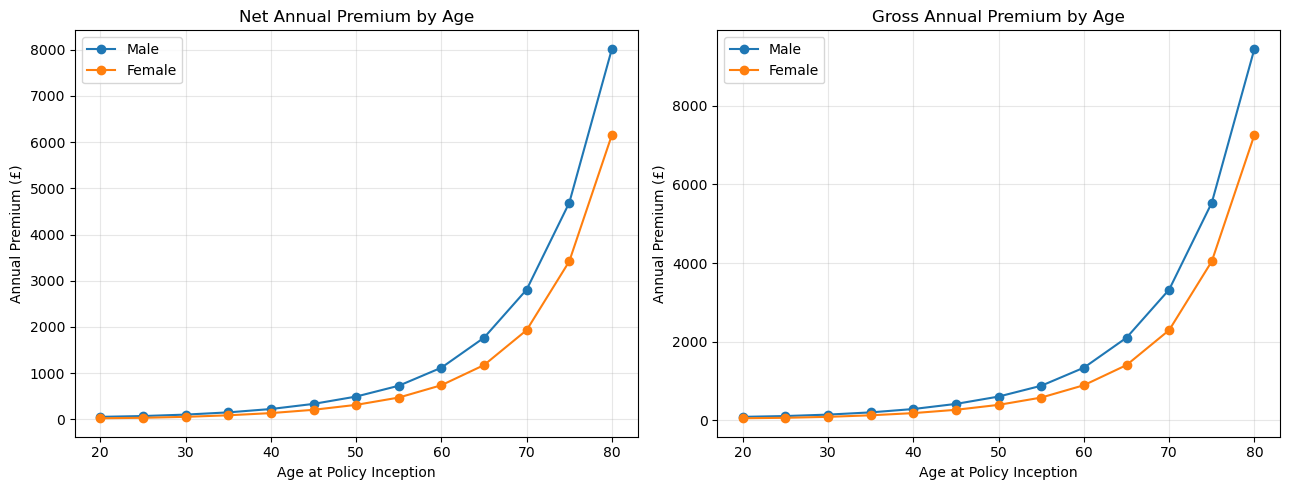

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for sex in ["Male", "Female"]:
    subset = pricing_df[pricing_df["Sex"] == sex]

    axes[0].plot(
        subset["Age"],
        subset["Net Premium"],
        marker="o",
        label=sex
    )

    axes[1].plot(
        subset["Age"],
        subset["Gross Premium"],
        marker="o",
        label=sex
    )

axes[0].set(
    title="Net Annual Premium by Age",
    xlabel="Age at Policy Inception",
    ylabel="Annual Premium (£)"
)

axes[1].set(
    title="Gross Annual Premium by Age",
    xlabel="Age at Policy Inception",
    ylabel="Annual Premium (£)"
)

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Monte Carlo Claims Simulation

### 3.1 Simulation Methodology

The actuarial pricing model developed in Chapter 2 calculates the expected present value of future claims. However, realised claims are random and may differ substantially from their expected value.

Monte Carlo simulation allows us to approximate the distribution of possible insurance outcomes by repeatedly simulating policyholder deaths.

#### Modelling Individual Policy Outcomes

Consider a policyholder aged $x$ purchasing an $n$-year term life insurance policy.

The probability of death during policy year $k+1$ is

$$
\pi_k = {}_kp_xq_{x+k},
\qquad k=0,\ldots,n-1.
$$

The probability of surviving the entire policy term is

$$
\pi_n = {}_np_x.
$$

These probabilities form a discrete probability distribution satisfying

$$
\sum_{k=0}^{n}\pi_k=1.
$$

Define the random variable $D$ as the policy year of death, with $D=n+1$ representing survival beyond the policy term.

Thus,

$$
P(D=k+1)=\pi_k,
\qquad k=0,\ldots,n-1,
$$

and

$$
P(D=n+1)=\pi_n.
$$

#### Simulating the Present Value of Claims

The present value of the death benefit is the random variable

$$
Z =
\begin{cases}
Bv^D, & D\leq n,\\
0, & D=n+1.
\end{cases}
$$

where $B$ is the death benefit and $v=(1+i)^{-1}$.

Its expectation is

$$
E[Z]
=
B\sum_{k=0}^{n-1}v^{k+1}{}_kp_xq_{x+k},
$$

which is precisely the analytical expected present value derived in Chapter 2.

By generating independent simulated values $Z_1,\ldots,Z_N$, we estimate the expected present value using

$$
\widehat{E[Z]}=\frac{1}{N}\sum_{j=1}^{N}Z_j.
$$

By the law of large numbers, this estimate converges to the theoretical expectation as the number of simulations increases, under the assumptions of the model.

In [24]:
def death_year_distribution(age, term, sex="Male"):
    """
    Probability of death in each policy year,
    plus survival beyond the policy term.
    """
    death_probs = np.array([
        survival_probability(age, k, sex)
        * mortality.loc[
            mortality["Age"] == age + k,
            f"{sex}_qx"
        ].iloc[0]
        for k in range(term)
    ])

    survival_prob = survival_probability(age, term, sex)

    probabilities = np.append(death_probs, survival_prob)

    assert np.isclose(probabilities.sum(), 1.0)
    assert np.all(probabilities >= 0)

    return probabilities


# Baseline policy
age = 40
term = 10
benefit = 100_000
interest_rate = 0.04
sex = "Male"

probabilities = death_year_distribution(age, term, sex)

distribution_df = pd.DataFrame({
    "Outcome": [
        f"Death in year {k}" for k in range(1, term + 1)
    ] + ["Survive policy term"],
    "Probability": probabilities
})

display(distribution_df)

,Outcome,Probability
0,Death in year 1,0.001681
1,Death in year 2,0.001805
2,Death in year 3,0.001883
3,Death in year 4,0.002063
4,Death in year 5,0.002148
5,Death in year 6,0.002410
6,Death in year 7,0.002584
7,Death in year 8,0.002798
8,Death in year 9,0.003004
9,Death in year 10,0.003318


In [27]:
# Set seed for reproducibility
rng = np.random.default_rng(42)

n_simulations = 1_000_000

# Outcomes 1–10 represent death years;
# outcome 11 represents survival beyond the term.
outcomes = np.arange(1, term + 2)

simulated_death_years = rng.choice(
    outcomes,
    size=n_simulations,
    p=probabilities
)

# Present value of each simulated claim
simulated_claims = np.where(
    simulated_death_years <= term,
    benefit * (1 + interest_rate) ** (-simulated_death_years),
    0.0
)

mc_expected_claim = simulated_claims.mean()

analytical_expected_claim = expected_present_value(
    age, term, benefit, interest_rate, sex
)

print(f"Monte Carlo expected claim: £{mc_expected_claim:,.2f}")
print(f"Analytical expected claim:  £{analytical_expected_claim:,.2f}")

relative_error = (
    abs(mc_expected_claim - analytical_expected_claim)
    / analytical_expected_claim
) * 100

print(f"Relative simulation error: {relative_error:.2f}%")

Monte Carlo expected claim: £1,870.08
Analytical expected claim:  £1,875.22
Relative simulation error: 0.27%


#### Monte Carlo Convergence

Increasing the number of simulated policy outcomes from 100,000 to 1,000,000 reduced the observed relative error against the analytical expected present value from 1.43% to 0.27%.

This provides empirical evidence of convergence towards the theoretical expectation, consistent with the law of large numbers.

The Monte Carlo standard error decreases proportionally to $N^{-1/2}$. Consequently, increasing the simulation count tenfold reduces the theoretical standard error by approximately 68.4%.

The observed reduction in error may differ from this theoretical relationship due to random sampling variation.

### 3.2 Portfolio Claims Simulation

We extend the individual policy model to a portfolio containing $M$ policyholders.

Each policyholder is assumed to have identical contractual characteristics and mortality probabilities, with deaths occurring independently across individuals.

For policyholder $j$, let $Z_j$ denote the present value of the death benefit:

$$
Z_j =
\begin{cases}
Bv^{D_j}, & D_j \leq n,\\
0, & D_j=n+1,
\end{cases}
$$

where $D_j$ is the simulated policy year of death, with $n+1$ representing survival beyond the policy term.

The aggregate present value of claims is

$$
\boxed{S_M=\sum_{j=1}^{M}Z_j}.
$$

#### Expected Aggregate Claims

By linearity of expectation,

$$
E[S_M]=\sum_{j=1}^{M}E[Z_j].
$$

For identical policies,

$$
\boxed{E[S_M]=M E[Z]}.
$$

#### Portfolio Variance

Assuming independent policyholder mortality outcomes,

$$
\operatorname{Var}(S_M)
=\sum_{j=1}^{M}\operatorname{Var}(Z_j)
=M\sigma_Z^2.
$$

Consequently,

$$
\boxed{\sigma_{S_M}=\sqrt{M}\sigma_Z}.
$$

The relative standard deviation is therefore

$$
\frac{\sigma_{S_M}}{E[S_M]}
=
\frac{\sigma_Z}{\sqrt{M}E[Z]}.
$$

This demonstrates the diversification effect: while expected aggregate claims increase linearly with portfolio size, the standard deviation increases only with the square root of portfolio size.

The result depends on independence. Correlated mortality shocks, such as pandemics, can weaken diversification benefits.

In [28]:
# Portfolio simulation parameters
n_policies = 1_000
n_portfolios = 10_000

# Reproducible random number generator
rng_portfolio = np.random.default_rng(123)

# Death-year probabilities from Section 3.1
probabilities = death_year_distribution(
    age=40,
    term=10,
    sex="Male"
)

# Simulate death counts across policy years
death_counts = rng_portfolio.multinomial(
    n=n_policies,
    pvals=probabilities,
    size=n_portfolios
)

# Present value of each possible claim
claim_values = np.array([
    100_000 * (1.04) ** (-k)
    for k in range(1, 11)
] + [0.0])

# Aggregate discounted claims for each portfolio
portfolio_claims = death_counts @ claim_values

print(f"Number of portfolios: {n_portfolios:,}")
print(f"Policies per portfolio: {n_policies:,}")
print(f"Mean portfolio claims: £{portfolio_claims.mean():,.2f}")
print(f"Standard deviation: £{portfolio_claims.std(ddof=1):,.2f}")

Number of portfolios: 10,000
Policies per portfolio: 1,000
Mean portfolio claims: £1,873,747.71
Standard deviation: £387,387.64


In [31]:
# Analytical expected aggregate claims
analytical_portfolio_epv = n_policies * expected_present_value(
    40, 10, 100_000, 0.04, "Male"
)

# Monte Carlo estimate
mc_portfolio_epv = portfolio_claims.mean()

# Relative error
portfolio_error = (
    abs(mc_portfolio_epv - analytical_portfolio_epv)
    / analytical_portfolio_epv
) * 100

# Monte Carlo standard error
portfolio_se = (
    portfolio_claims.std(ddof=1)
    / np.sqrt(n_portfolios)
)

print(f"Analytical expected claims: £{analytical_portfolio_epv:,.2f}")
print(f"Monte Carlo expected claims: £{mc_portfolio_epv:,.2f}")
print(f"Relative error: {portfolio_error:.3f}%")
print(f"Monte Carlo standard error: £{portfolio_se:,.2f}")

Analytical expected claims: £1,875,223.94
Monte Carlo expected claims: £1,873,747.71
Relative error: 0.079%
Monte Carlo standard error: £3,873.88


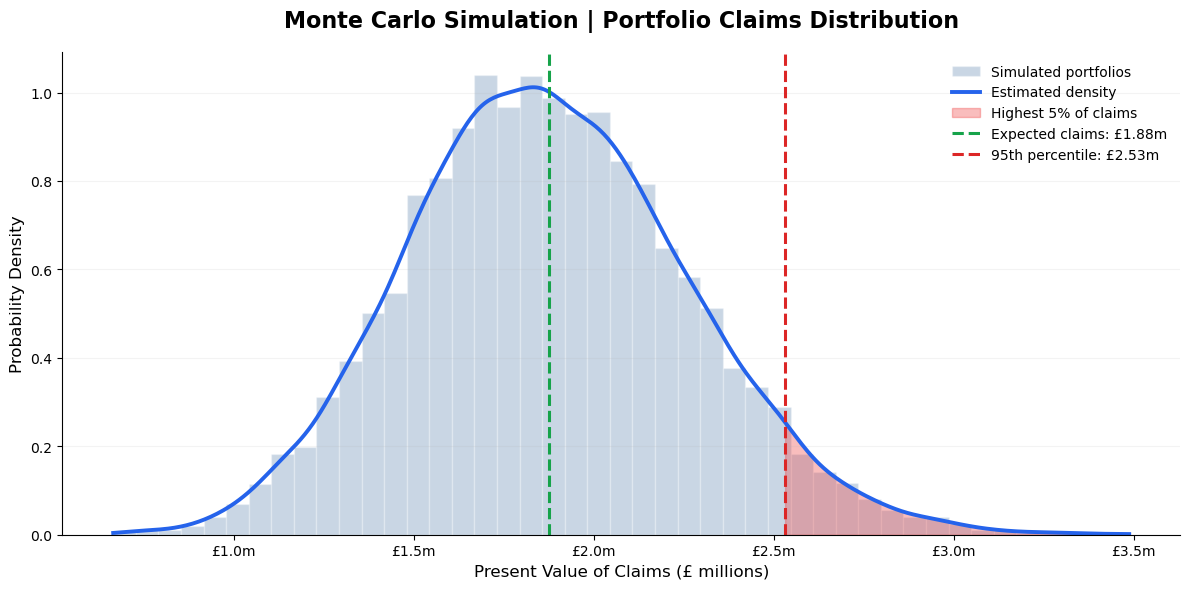

In [33]:
from scipy.stats import gaussian_kde
from matplotlib.ticker import FuncFormatter

# Convert claims into £ millions
claims_m = portfolio_claims / 1_000_000

mean_claims = analytical_portfolio_epv / 1_000_000
var_95 = np.percentile(claims_m, 95)

# Smooth density estimate
x = np.linspace(claims_m.min(), claims_m.max(), 500)
kde = gaussian_kde(claims_m)
density = kde(x)

fig, ax = plt.subplots(figsize=(12, 6))

# Histogram
ax.hist(
    claims_m,
    bins=45,
    density=True,
    color="#4C78A8",
    alpha=0.30,
    edgecolor="white",
    label="Simulated portfolios"
)

# Smooth density curve
ax.plot(
    x, density,
    color="#2563EB",
    linewidth=2.8,
    label="Estimated density"
)

# Highlight worst 5% of outcomes
ax.fill_between(
    x, density,
    where=x >= var_95,
    color="#EF4444",
    alpha=0.35,
    label="Highest 5% of claims"
)

# Expected claims
ax.axvline(
    mean_claims,
    color="#16A34A",
    linestyle="--",
    linewidth=2.2,
    label=f"Expected claims: £{mean_claims:.2f}m"
)

# 95th percentile
ax.axvline(
    var_95,
    color="#DC2626",
    linestyle="--",
    linewidth=2.2,
    label=f"95th percentile: £{var_95:.2f}m"
)

# Formatting
ax.set_title(
    "Monte Carlo Simulation | Portfolio Claims Distribution",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Present Value of Claims (£ millions)", fontsize=12)
ax.set_ylabel("Probability Density", fontsize=12)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"£{value:.1f}m")
)

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.15)

ax.legend(frameon=False, fontsize=10)

plt.tight_layout()
plt.show()

### 3.3 Analytical vs Monte Carlo Validation

In Section 3.2, we validated the simulated mean aggregate claims against the analytical expected present value.

We now extend this validation to the variance and standard deviation of aggregate claims.

#### Individual Claim Variance

Let $Z$ denote the discounted claim payment for an individual policy.

The expected value is

$$
E[Z]=B\sum_{k=0}^{n-1}v^{k+1}{}_kp_xq_{x+k}.
$$

To calculate the variance, we use

$$
\operatorname{Var}(Z)=E[Z^2]-(E[Z])^2.
$$

Since the discounted claim is $Bv^{k+1}$ if death occurs during policy year $k+1$, its second moment is

$$
E[Z^2]
=
B^2\sum_{k=0}^{n-1}v^{2(k+1)}{}_kp_xq_{x+k}.
$$

Therefore,

$$
\boxed{
\operatorname{Var}(Z)
=
B^2\sum_{k=0}^{n-1}v^{2(k+1)}{}_kp_xq_{x+k}
-
(E[Z])^2
}.
$$

#### Aggregate Portfolio Variance

For a portfolio of $M$ independent, identically distributed policies,

$$
S_M=\sum_{j=1}^{M}Z_j.
$$

Independence implies

$$
\boxed{\operatorname{Var}(S_M)=M\operatorname{Var}(Z)}.
$$

Consequently,

$$
\boxed{\sigma_{S_M}=\sqrt{M}\sigma_Z}.
$$

We compare these analytical results with the sample mean and standard deviation obtained from our Monte Carlo simulation.

Agreement provides evidence that the simulation correctly reproduces the first two moments of the assumed claims distribution.

In [36]:
def analytical_claim_variance(
    age, term, benefit, interest_rate, sex="Male"
):
    """
    Analytical variance of the discounted death benefit
    for an individual term life insurance policy.
    """
    probabilities = death_year_distribution(
        age, term, sex
    )

    claim_values = np.array([
        benefit * (1 + interest_rate) ** (-k)
        for k in range(1, term + 1)
    ] + [0.0])

    expected_claim = np.sum(probabilities * claim_values)

    second_moment = np.sum(
        probabilities * claim_values**2
    )

    return second_moment - expected_claim**2


# Analytical portfolio statistics
individual_variance = analytical_claim_variance(
    40, 10, 100_000, 0.04, "Male"
)

analytical_portfolio_std = np.sqrt(
    n_policies * individual_variance
)

# Monte Carlo portfolio statistics
mc_portfolio_std = portfolio_claims.std(ddof=1)

std_error_pct = (
    abs(mc_portfolio_std - analytical_portfolio_std)
    / analytical_portfolio_std
) * 100

print(f"Analytical portfolio SD: £{analytical_portfolio_std:,.2f}")
print(f"Monte Carlo portfolio SD: £{mc_portfolio_std:,.2f}")
print(f"Relative difference: {std_error_pct:.3f}%")

Analytical portfolio SD: £383,146.53
Monte Carlo portfolio SD: £387,387.64
Relative difference: 1.107%


In [37]:
validation_df = pd.DataFrame({
    "Statistic": [
        "Expected Claims",
        "Standard Deviation"
    ],
    "Analytical": [
        analytical_portfolio_epv,
        analytical_portfolio_std
    ],
    "Monte Carlo": [
        portfolio_claims.mean(),
        portfolio_claims.std(ddof=1)
    ]
})

validation_df["Relative Error (%)"] = (
    abs(
        validation_df["Monte Carlo"]
        - validation_df["Analytical"]
    )
    / validation_df["Analytical"]
) * 100

display(validation_df.round(3))

,Statistic,Analytical,Monte Carlo,Relative Error (%)
0,Expected Claims,1875223.938,1873747.709,0.079
1,Standard Deviation,383146.526,387387.637,1.107


### 3.4 Portfolio Profitability

Having modelled the distribution of aggregate claims, we now examine the profitability of our simulated insurance portfolios.

An insurer receives annual premium payments from policyholders, while incurring death benefit payments and operating expenses.

For a portfolio containing $M$ policies, the present value of profit is

$$
\boxed{
\Pi_M = PV(\text{Premiums}) - PV(\text{Claims}) - PV(\text{Expenses})
}
$$

Premiums are paid at the beginning of each policy year while the policyholder remains alive. Annual maintenance expenses follow the same payment schedule, while death benefits are paid at the end of the year of death.

#### Expected Portfolio Profit

Recall the gross premium formula from Chapter 2:

$$
P_g = \frac{C+E_0+ea}{(1-\lambda)a},
$$

where:

- $C$ is the expected present value of claims per policy.
- $E_0$ is the initial expense.
- $e$ is the annual maintenance expense.
- $a$ is the temporary life annuity-due factor.
- $\lambda$ is the premium loading.

Rearranging,

$$
P_ga-C-E_0-ea=\lambda P_ga.
$$

Therefore, the analytical expected profit for a portfolio of $M$ identical policies is

$$
\boxed{E[\Pi_M]=M\lambda P_ga}.
$$

We will compare this analytical result with the average profitability obtained from our Monte Carlo simulation.

In [42]:
# Policy assumptions
age = 40
term = 10
benefit = 100_000
interest_rate = 0.04
sex = "Male"

initial_expense = 50
annual_expense = 10
loading = 0.15

# Gross annual premium
gross_premium = gross_annual_premium(
    age, term, benefit, interest_rate, sex,
    initial_expense=initial_expense,
    annual_expense=annual_expense,
    loading=loading
)

# Number of premium payments for each death-year outcome
outcomes = np.arange(1, term + 2)
premium_counts = np.minimum(outcomes, term)

# Discounted premium payment factors
premium_factors = np.array([
    sum((1 + interest_rate)**(-t) for t in range(k))
    for k in premium_counts
])

# Total discounted premium payment factors per portfolio
portfolio_annuity_factors = death_counts @ premium_factors

# Portfolio cash flows
portfolio_premiums = gross_premium * portfolio_annuity_factors

portfolio_expenses = (
    n_policies * initial_expense
    + annual_expense * portfolio_annuity_factors
)

# Portfolio profitability
portfolio_profit = (
    portfolio_premiums
    - portfolio_claims
    - portfolio_expenses
)

# Analytical expected profitability
a = annuity_due_factor(age, term, interest_rate, sex)

analytical_profit = (
    n_policies * loading * gross_premium * a
)

print(f"Gross annual premium: £{gross_premium:,.2f}")
print(f"Analytical expected profit: £{analytical_profit:,.2f}")
print(f"Simulated mean profit: £{portfolio_profit.mean():,.2f}")

Gross annual premium: £282.57
Analytical expected profit: £354,505.28
Simulated mean profit: £355,962.12


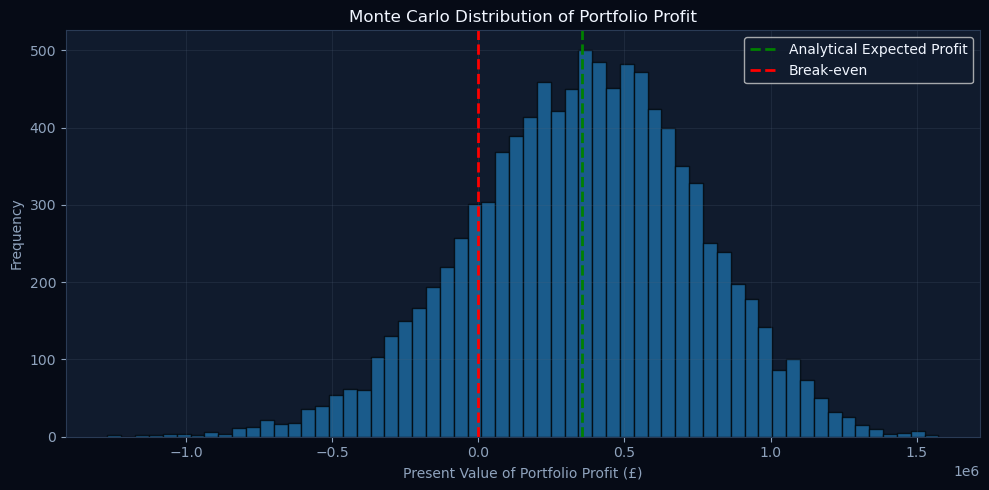

In [45]:
# Portfolio profitability distribution
plt.figure(figsize=(10, 5))

plt.hist(
    portfolio_profit,
    bins=60,
    alpha=0.7,
    edgecolor="black"
)

plt.axvline(
    analytical_profit,
    color="green",
    linestyle="--",
    linewidth=2,
    label="Analytical Expected Profit"
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Break-even"
)

plt.title("Monte Carlo Distribution of Portfolio Profit")
plt.xlabel("Present Value of Portfolio Profit (£)")
plt.ylabel("Frequency")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


---

# 4. Conclusion and Key Findings

This project investigated the application of probability theory, actuarial mathematics and Monte Carlo simulation to life insurance pricing and portfolio profitability.

Using UK mortality data from the Office for National Statistics (ONS), we developed a model for estimating death and survival probabilities, calculating insurance premiums and simulating the financial outcomes of a portfolio of term life insurance policies.

### Key Findings

**1. Mortality and Actuarial Pricing**

Mortality probabilities were used to calculate the expected present value of future death benefits. By incorporating discounting, operating expenses and a profit loading, we derived net and gross annual premiums for a range of policyholder ages.

The results demonstrated how mortality assumptions, policyholder age and financial assumptions influence the cost of providing life insurance.

**2. Monte Carlo Simulation and Model Validation**

Monte Carlo methods were used to simulate individual death outcomes and aggregate claims across insurance portfolios.

The simulated expected claims were compared with analytical results, demonstrating consistency between the stochastic simulation and the underlying actuarial model.

The portfolio simulations also illustrated how aggregating independent insurance risks reduces relative uncertainty through diversification.

**3. Portfolio Profitability**

By combining simulated claims with premium income and operating expenses, we investigated the profitability of a portfolio of term life insurance policies.

The results demonstrated that although premiums can be designed to generate positive expected profit, realised profitability varies because of uncertainty in the number and timing of death claims.

### Final Remarks

The project demonstrates how mathematical models can translate uncertain future events into quantitative estimates that support insurance pricing decisions.

Combining analytical actuarial calculations with Monte Carlo simulation provided both a theoretical understanding of expected insurance costs and a practical framework for investigating portfolio outcomes.

While the model relies on simplifying assumptions, including independent mortality outcomes, fixed interest rates and identical policy characteristics, it provides a foundation for understanding the mathematical principles underlying actuarial pricing and insurance risk management.
